In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FILE_PATH = "upregulated_DEGs.csv"
DISEASE_NAME = "IPF"
GROUP_TAG = "Upregulated DEG"


results_df = pd.read_csv(FILE_PATH, index_col=0)


print(f"Successfully loaded data! Dimensions: {results_df.shape}")
print(results_df.head(2))

Successfully loaded data! Dimensions: (65, 3)
              p_value   log2_FC  p_value_bonf
symbol                                       
PROM1    8.631725e-13  2.333169  9.578625e-09
CYP24A1  7.265035e-21  2.322824  8.062009e-17


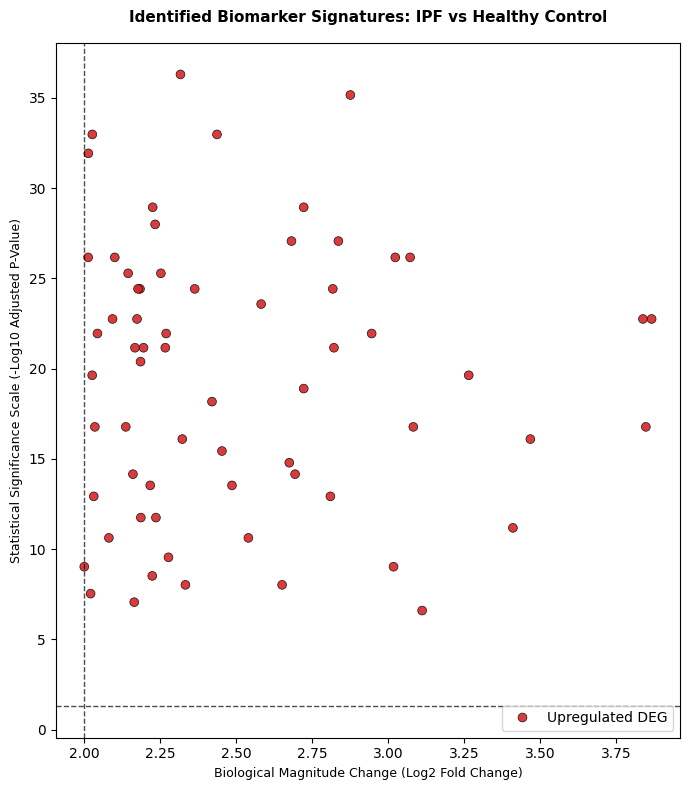

In [5]:
results_df['-log10_p'] = -np.log10(results_df['p_value_bonf'])


results_df['Expression_Status'] = GROUP_TAG

plt.figure(figsize=(7, 8), dpi=100)

sns.scatterplot(data=results_df, x='log2_FC', y='-log10_p', hue='Expression_Status', palette={GROUP_TAG: '#d62728'},alpha=0.9, s=40,edgecolor='black',linewidth=0.5)



plt.axhline(y=-np.log10(0.05), color='black', linestyle='--', linewidth=1, alpha=0.7)
plt.axvline(x=2, color='black', linestyle='--', linewidth=1, alpha=0.7)


plt.title(f"Identified Biomarker Signatures: {DISEASE_NAME} vs Healthy Control", fontsize=11, fontweight='bold', pad=15)
plt.xlabel("Biological Magnitude Change (Log2 Fold Change)", fontsize=9)
plt.ylabel("Statistical Significance Scale (-Log10 Adjusted P-Value)", fontsize=9)

plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.savefig(f"{DISEASE_NAME.lower()}_volcano_plot.png", dpi=300)
plt.show()

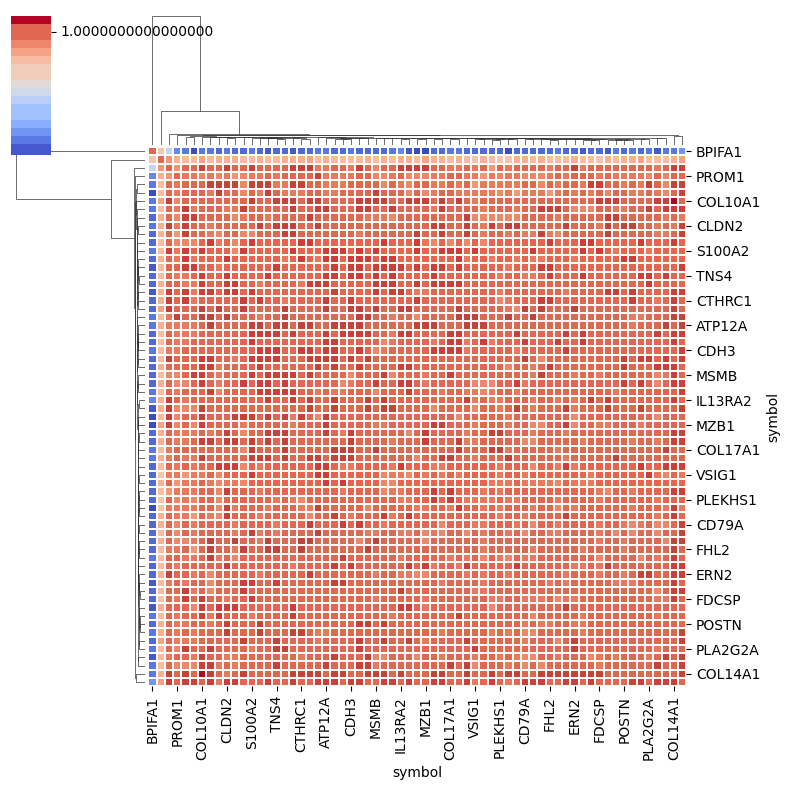

In [6]:
numerical_data = results_df[['p_value', 'log2_FC', 'p_value_bonf']]


correlation_matrix = numerical_data.T.corr()


clustermap_figure = sns.clustermap(correlation_matrix,cmap="coolwarm",figsize=(8, 8),linewidths=0.1, annot=False)

plt.savefig(f"{DISEASE_NAME.lower()}_gene_clustermap.png", dpi=300)
plt.show()


In [10]:
!pip install gseapy

import gseapy as gp


results_df = results_df.sort_values(by='log2_FC', ascending=False)


results_df.index = results_df.index.astype(str).str.upper().str.strip()


rnk_ranking_series = results_df['log2_FC']

print("Ranked genomic coordinates ready for GSEA lookup:")
print(rnk_ranking_series.head(3))


gsea_results = gp.prerank(rnk=rnk_ranking_series,gene_sets='GO_Biological_Process_2021',permutation_num=100,min_size=1,max_size=500)


pathway_table = gsea_results.res2d.sort_values(by='NES', ascending=False)
significant_pathways = pathway_table[pathway_table['FDR q-val'] <= 0.05]


significant_pathways.to_csv(f"{DISEASE_NAME.lower()}_discovered_pathways.csv")

print(f"\nPathway Search Complete! Identified {len(significant_pathways)} significant biological pathways.")
if not significant_pathways.empty:
   print(significant_pathways[['Term', 'NES', 'FDR q-val']].head(5))

Ranked genomic coordinates ready for GSEA lookup:
symbol
CXCL13    3.866199
FDCSP     3.847199
S100A2    3.837591
Name: log2_FC, dtype: float64

Pathway Search Complete! Identified 0 significant biological pathways.


In [12]:
print("--- Top 5 Discovered Enrichment Hits ---")
print(pathway_table[['Term', 'NES', 'FDR q-val', 'NOM p-val']].head(5))

if not pathway_table.empty:

    top_term = str(pathway_table['Term'].iloc[0])
    print(f"\nVisualizing the top pathway: {top_term}")


    from gseapy import gseaplot

    fig = gseaplot(rank_metric=gsea_results.ranking,term=top_term,**gsea_results.results[top_term],ofname=f"{DISEASE_NAME.lower()}_top_enrichment_mountain.png")
else:
    print("No pathways found in the table to plot.")

--- Top 5 Discovered Enrichment Hits ---
                                                 Term       NES  FDR q-val  \
4                            proteolysis (GO:0006508)  1.529283        1.0   
7   antimicrobial humoral immune response mediated...  1.447004        1.0   
8          defense response to bacterium (GO:0042742)  1.399773        1.0   
9        regulation of B cell activation (GO:0050864)  1.349467        1.0   
10                      limb development (GO:0060173)  1.330786        1.0   

    NOM p-val  
4    0.071429  
7    0.130435  
8    0.109375  
9    0.104478  
10   0.105263  

Visualizing the top pathway: proteolysis (GO:0006508)


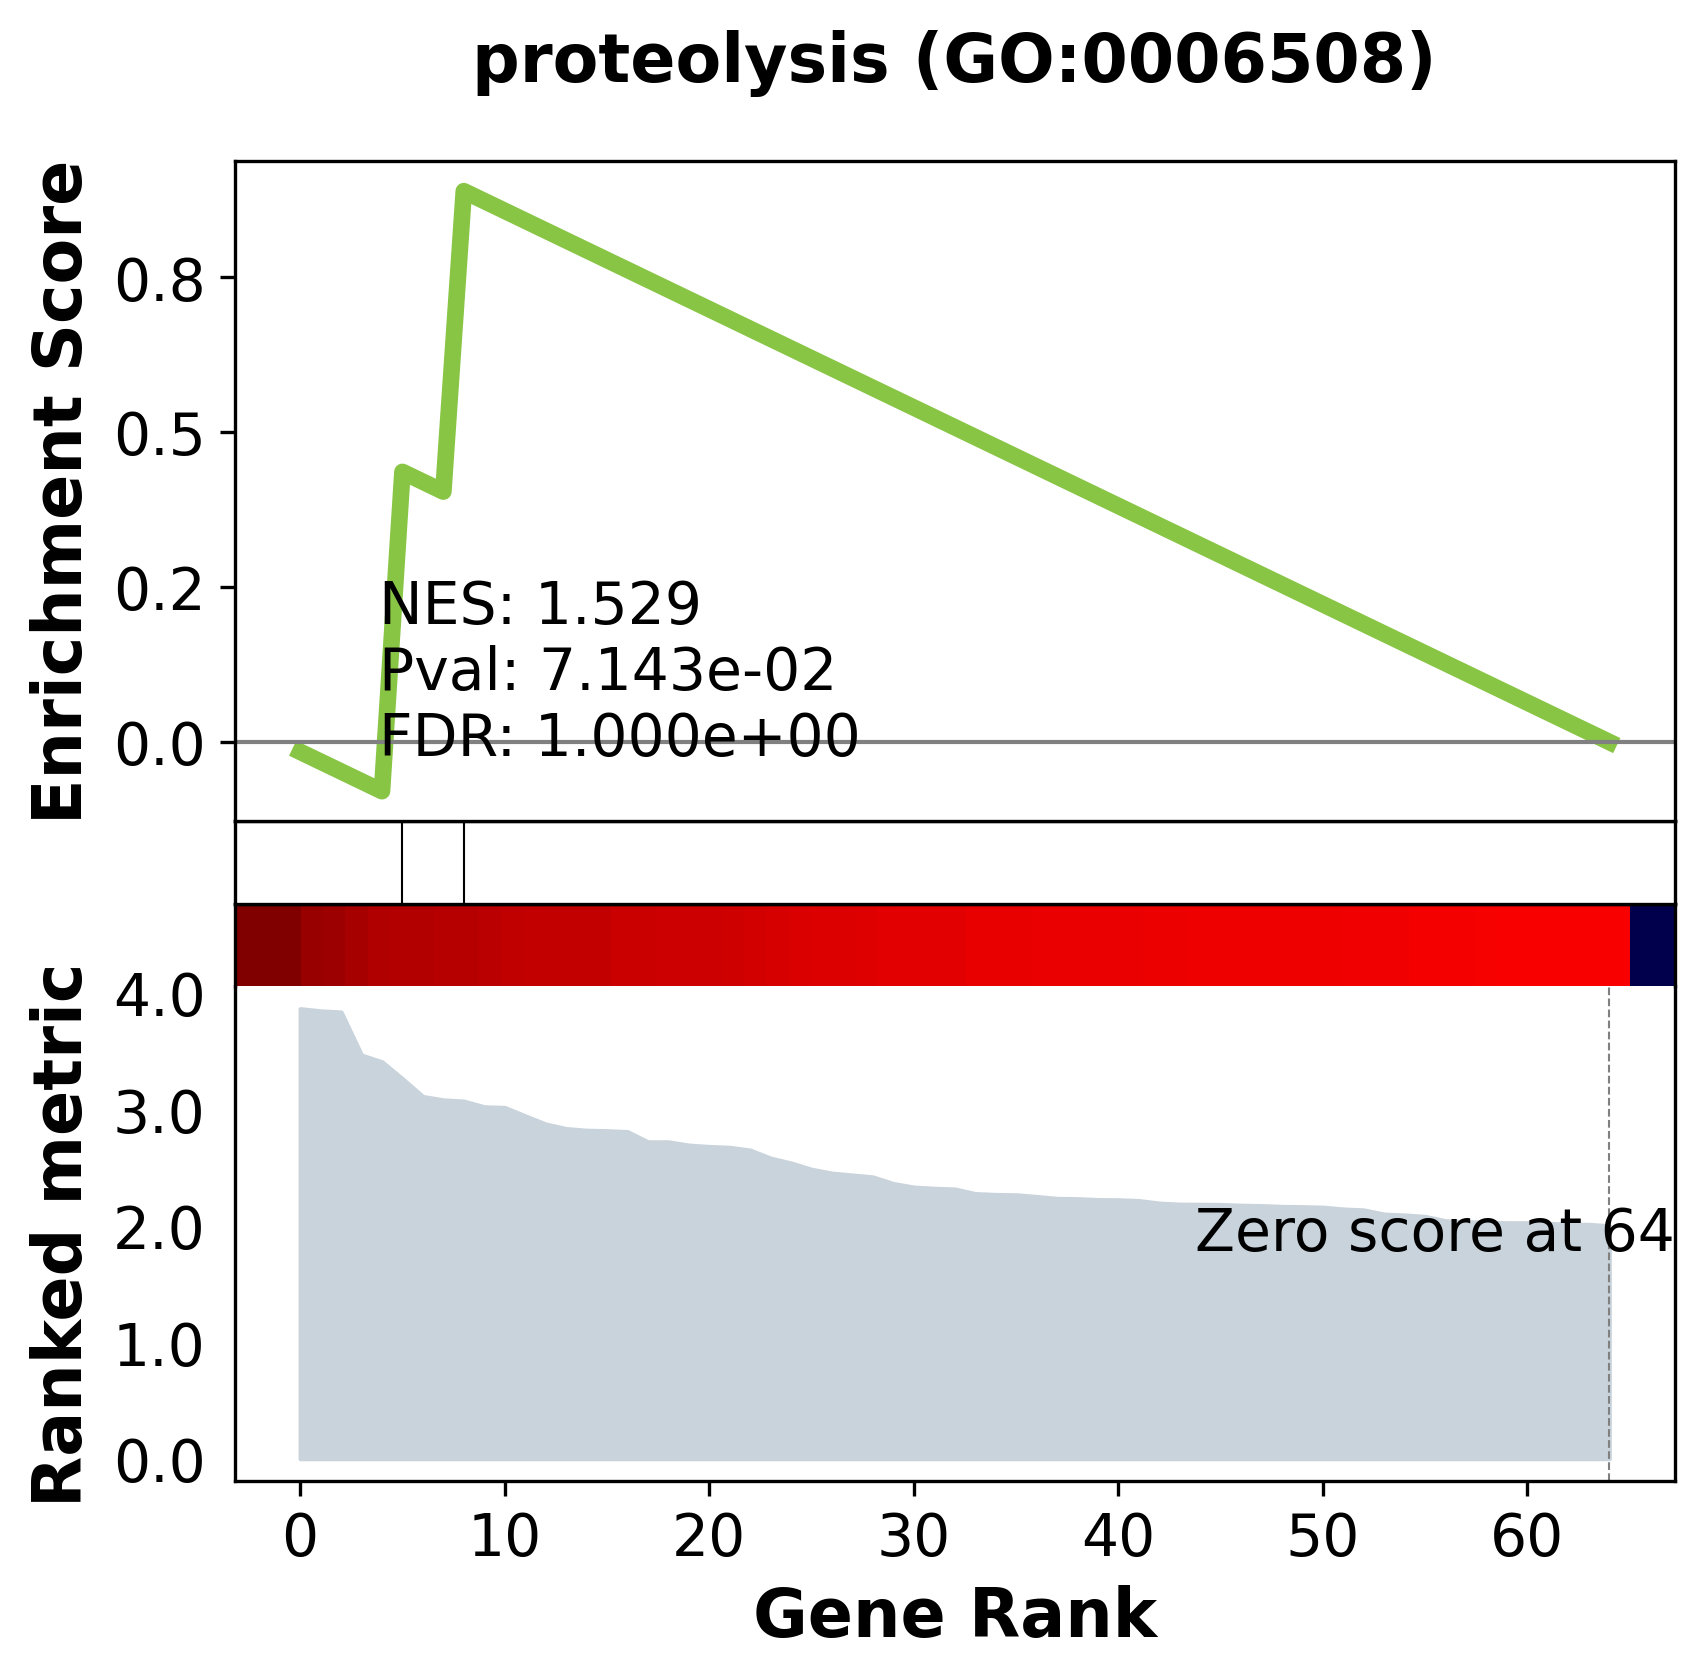

In [13]:
from IPython.display import Image, display


display(Image(filename="ipf_top_enrichment_mountain.png", width=600))


Plotting the mountain distribution curve for: proteolysis (GO:0006508)


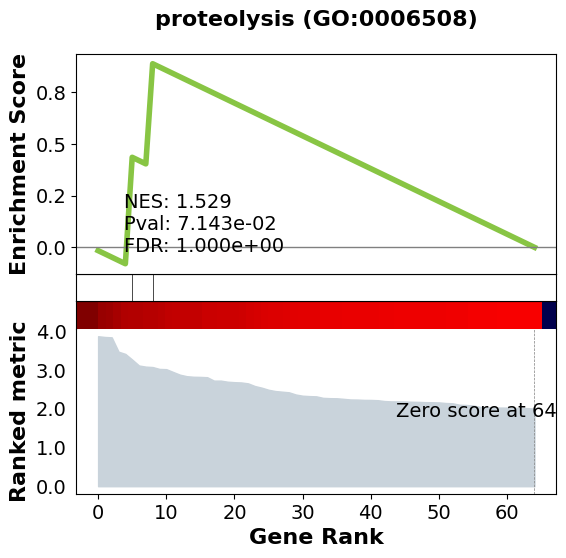

In [15]:
if not pathway_table.empty:

   top_discovered_pathway = str(pathway_table['Term'].iloc[0])
   print(f"Plotting the mountain distribution curve for: {top_discovered_pathway}")


   from gseapy import gseaplot
   fig=gseaplot(rank_metric=gsea_results.ranking,term=top_discovered_pathway,**gsea_results.results[top_discovered_pathway])


   import matplotlib.pyplot as plt
   plt.savefig(f"{DISEASE_NAME.lower()}_top_pathway_mountain.png", dpi=300, bbox_inches='tight')
   plt.show()
else:
   print("Your pathway results table is completely empty. Double-check your input gene ranking series.")